## Pregunta 1 — Eliminación de ruido periódico mediante filtrado notch

### Importaciones

In [1]:
# %pip install rawpy
import numpy as np
import matplotlib.pyplot as plt
import cv2
import rawpy

import p1_implementacion as p1

import os
os.makedirs('results', exist_ok=True)
os.makedirs(os.path.join('results', 'p1'), exist_ok=True)

In [2]:
import importlib
importlib.reload(p1)

<module 'p1_implementacion' from 'c:\\Users\\apfib\\OneDrive\\Desktop\\IEE2714\\t3-IEE2714\\p1_implementacion.py'>

### Imagen con ruido periodico

In [3]:
# Cargar imagen
ruta_origen = 'tarea3_files/P1.CR2'
with rawpy.imread(ruta_origen) as raw:
    # output_bps=16 configura la salida a 16 bits (valores de 0 a 65535)
    rgb = raw.postprocess(output_bps=16)

# Convertir a escala de grises y normalizar usando el rango de 16 bits
img = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 65535.0
M, N = img.shape
print(f"Imagen cargada con dimensiones: {M}x{N}")

Imagen cargada con dimensiones: 2856x4290


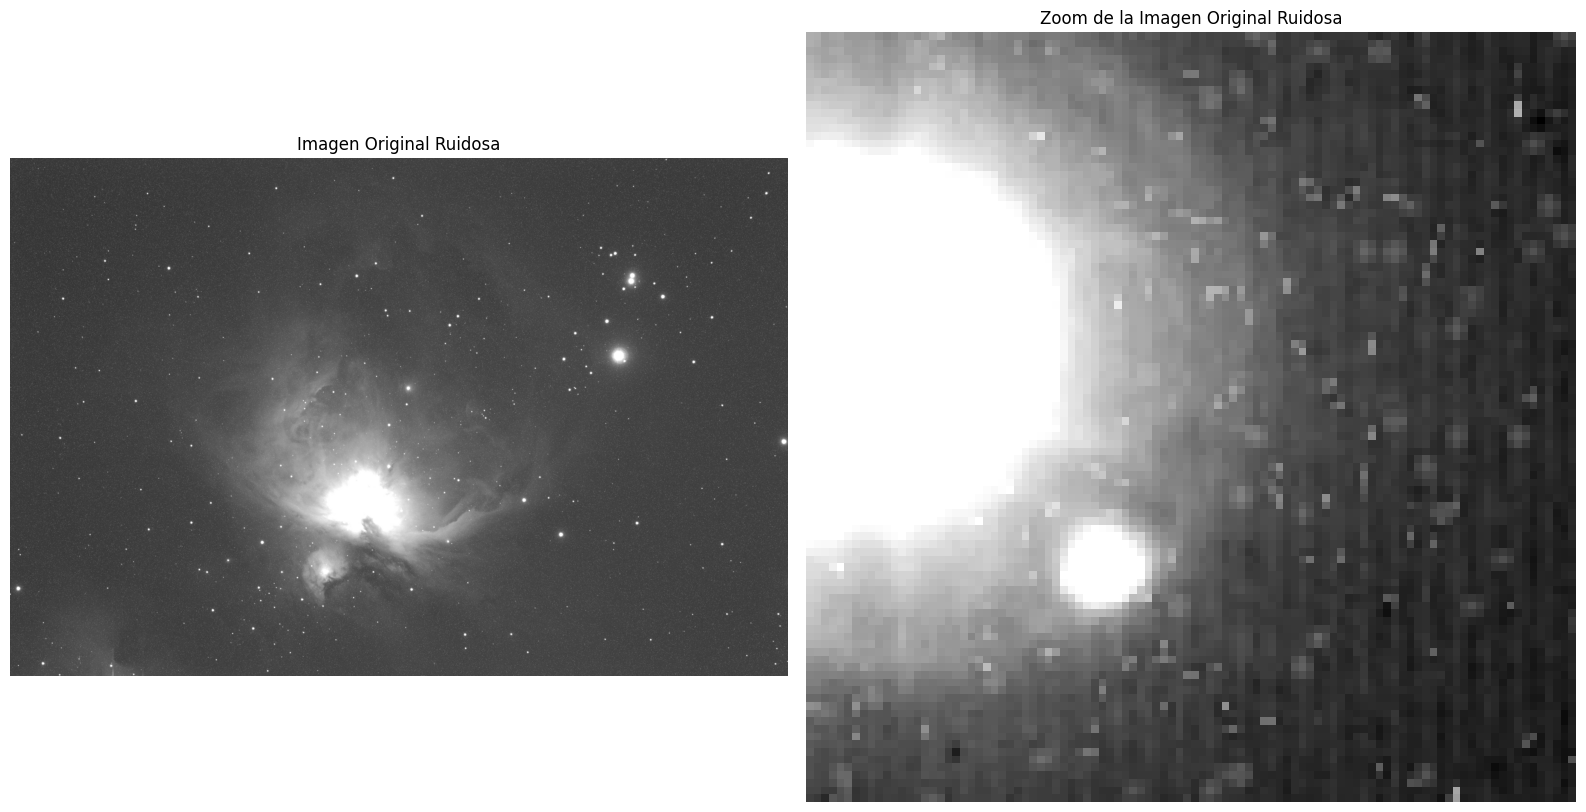

In [4]:
# Región que se desea ampliar
y1, y2 = 1050, 1150
x1, x2 = 3350, 3450

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Imagen original
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Imagen Original Ruidosa")
axes[0].axis("off")

# Región ampliada
axes[1].imshow(
    img[y1:y2, x1:x2],
    cmap="gray",
    interpolation="nearest"
)
axes[1].set_title("Zoom de la Imagen Original Ruidosa")
axes[1].axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join("results", "p1", "img_original_con_zoom.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Se observa ruido periódioco vertical

### 1. Muestre el espectro de magnitud de la imagen, identifique las componentes que atribuye al ruido periódico y justifique las posiciones seleccionadas para los notches.

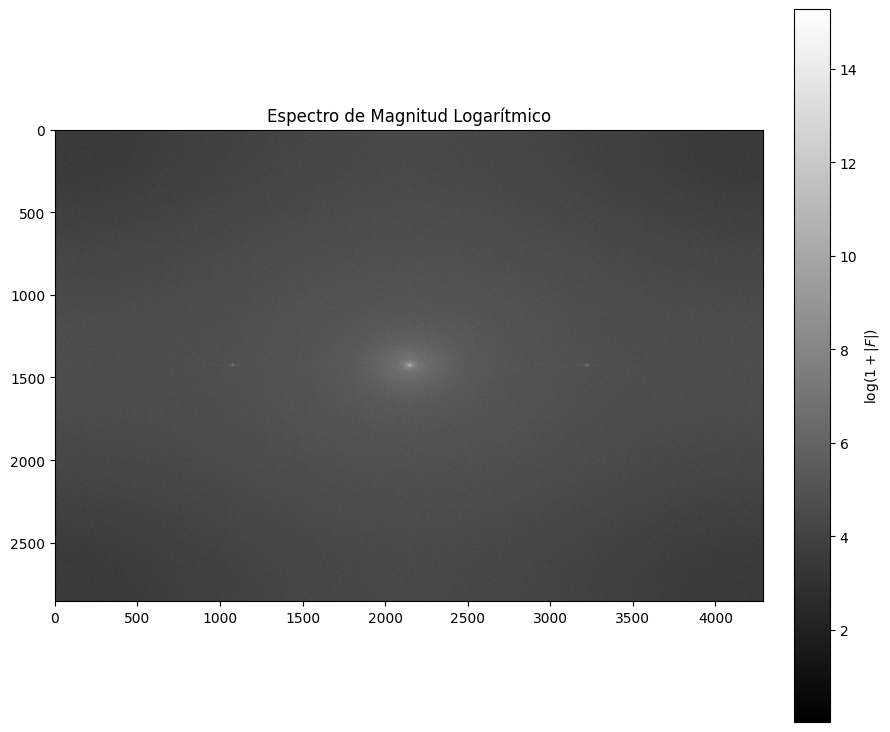

In [5]:
# Calcular la FFT 2D y el espectro de magnitud
F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)
magnitud = np.abs(F_shift)
magnitud_log = np.log(1 + magnitud)

# Visualizar el espectro de magnitud
plt.figure(figsize=(10, 10))
plt.imshow(magnitud_log, cmap='gray')
plt.colorbar(fraction=0.046, pad=0.04, label=r"$\log(1 + |F|)$")
plt.title('Espectro de Magnitud Logarítmico')
plt.savefig(
    os.path.join('results', 'p1', 'espectro_magnitud.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()
del F, F_shift

In [6]:
# Detección de los picos de ruido
centro_y, centro_x = M // 2, N // 2
mask_centro = np.ones((M, N), dtype=bool)
radio_centro = min(M, N) * 0.05  # Máscara para ignorar el centro DC
y_grid, x_grid = np.ogrid[:M, :N]
dist_from_center = np.sqrt((y_grid - centro_y)**2 + (x_grid - centro_x)**2)
mask_centro[dist_from_center < radio_centro] = False

# Encontrar los picos de mayor magnitud fuera de DC
mag_no_dc = np.where(mask_centro, magnitud, 0)
num_picos = 2  # Par simétrico
indices_flat = np.argsort(mag_no_dc.ravel())[::-1][:num_picos]
picos_coords = [np.unravel_index(idx, (M, N)) for idx in indices_flat]

print("\n--- Picos de Ruido Periódico Identificados ---")
centros_notch = []
for i, (ry, rx) in enumerate(picos_coords):
    u_rel = ry - centro_y
    v_rel = rx - centro_x
    val_mag = magnitud[ry, rx]
    print(f"Pico {i+1}: Absoluto (Fila={ry}, Col={rx}) | Relativo al centro (u={u_rel}, v={v_rel}) | Magnitud={val_mag:.2f}")
    centros_notch.append((u_rel, v_rel))


--- Picos de Ruido Periódico Identificados ---
Pico 1: Absoluto (Fila=1428, Col=1072) | Relativo al centro (u=0, v=-1073) | Magnitud=72216.74
Pico 2: Absoluto (Fila=1428, Col=3218) | Relativo al centro (u=0, v=1073) | Magnitud=72216.74


1. Se calcula la transformada de Fourier bidimensional y su respectivo espectro de magnitud en escala logarítmica para visualizar las componentes frecuenciales de la imagen.
2. Se observan dos picos de energía que corresponden al ruido periodico en (Fila=1428, Col=1072 y 3218)
3. Mediante un algoritmo de búsqueda que enmascara la región central, se identifican automáticamente los picos de mayor energía fuera del origen para encontrar las coords exactas.

Coords detectadas: Se localiza un par simétrico ubicado en las coordenadas relativas $(u=0, v=\pm 1073)$ con una magnitud de $72,216.74$.

Justificación: Al encontrarse sobre el eje horizontal ($u=0$), estos picos reflejan matemáticamente la presencia de interferencia periódica vertical vista en la imagen espacial. Los centros de los filtros notch se configuran exactamente en estas coordenadas para atenuar componentes simétricas.

### 2. Para ambas familias de filtro, explore sistemáticamente varios anchos de notch. Para los casos principales muestre la imagen filtrada, el espectro antes y después del filtrado y una imagen diferencia entre la imagen ruidosa y la filtrada, usando una escala común. Analice conjuntamente ruido residual, pérdida de detalle y artefactos. 

In [7]:
D0_values = [10,20,30,60,120,400]
resultados_radio = {"ideal":{}, "gaussiano":{}}

for tipo in ("ideal","gaussiano"):
    for D0 in D0_values:
        ns = [(u,v,float(D0)) for u,v in centros_notch]
        res = p1.filtrar_frecuencia_notch(img, ns, tipo,
                                       modo_padding="none", factor_padding=1.0)
        resultados_radio[tipo][D0] = {
            "imagen":res["imagen"],
            "diferencia":res["diferencia"],
            "media_diferencia":float(np.mean(res["diferencia"])),
        }
        del res
print("Exploración terminada.")

Exploración terminada.


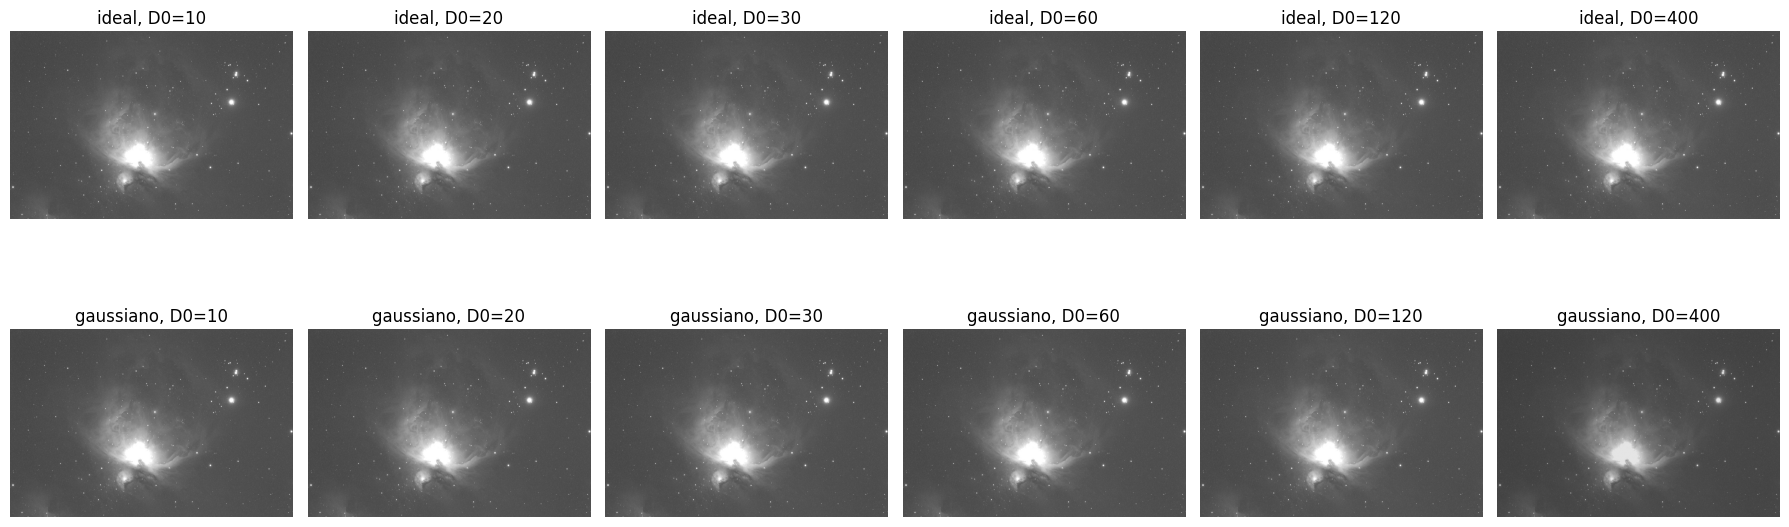

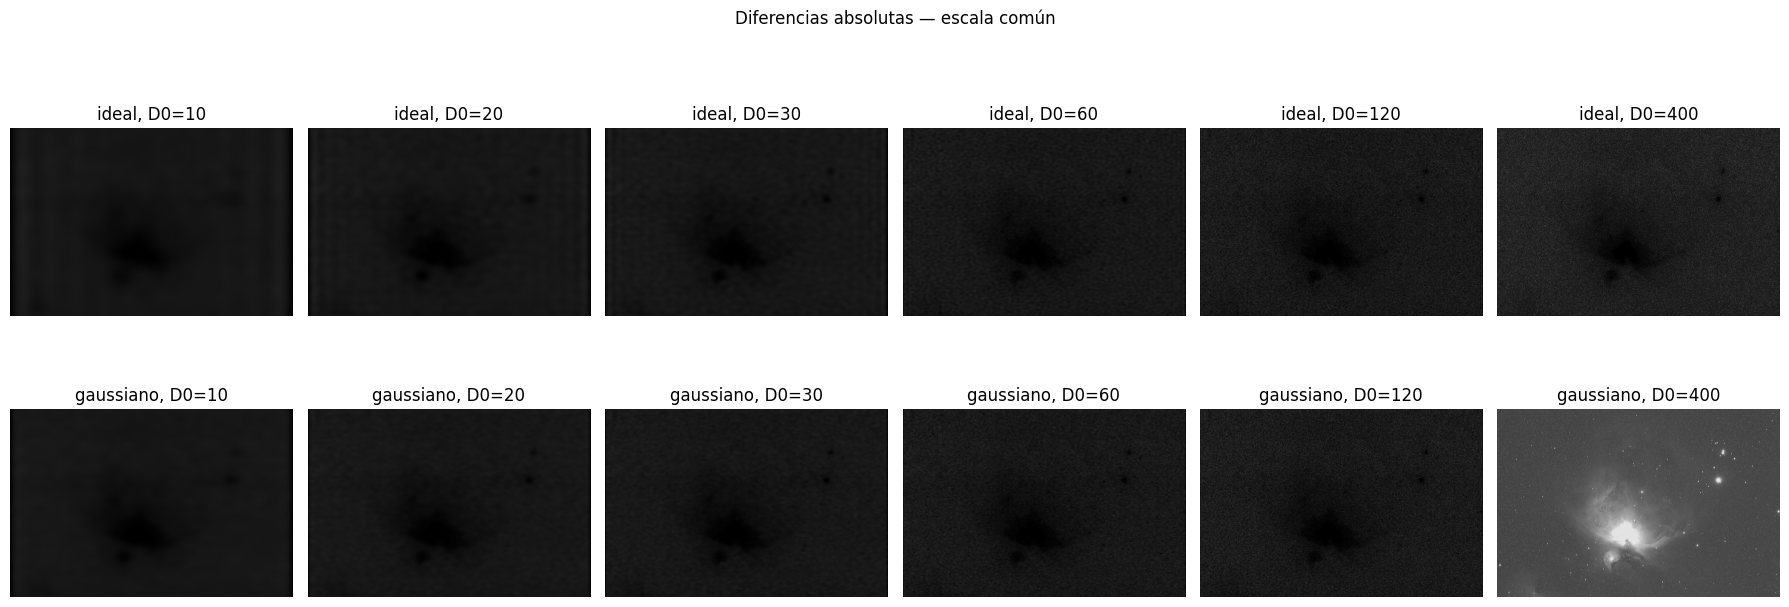

In [8]:
fig, axes = plt.subplots(2,len(D0_values),figsize=(18,7))
for i,tipo in enumerate(("ideal","gaussiano")):
    for j,D0 in enumerate(D0_values):
        axes[i,j].imshow(resultados_radio[tipo][D0]["imagen"],cmap="gray",vmin=0,vmax=1)
        axes[i,j].set_title(f"{tipo}, D0={D0}")
        axes[i,j].axis("off")
plt.tight_layout()
plt.show()

vmax_comun = max(np.percentile(resultados_radio[t][d]["diferencia"],99.5)
                 for t in ("ideal","gaussiano") for d in D0_values)
fig, axes = plt.subplots(2,len(D0_values),figsize=(18,7))
for i,tipo in enumerate(("ideal","gaussiano")):
    for j,D0 in enumerate(D0_values):
        axes[i,j].imshow(resultados_radio[tipo][D0]["diferencia"],
                         cmap="gray",vmin=0,vmax=max(vmax_comun,1e-9))
        axes[i,j].set_title(f"{tipo}, D0={D0}")
        axes[i,j].axis("off")
plt.suptitle("Diferencias absolutas — escala común")
plt.tight_layout()
plt.show()

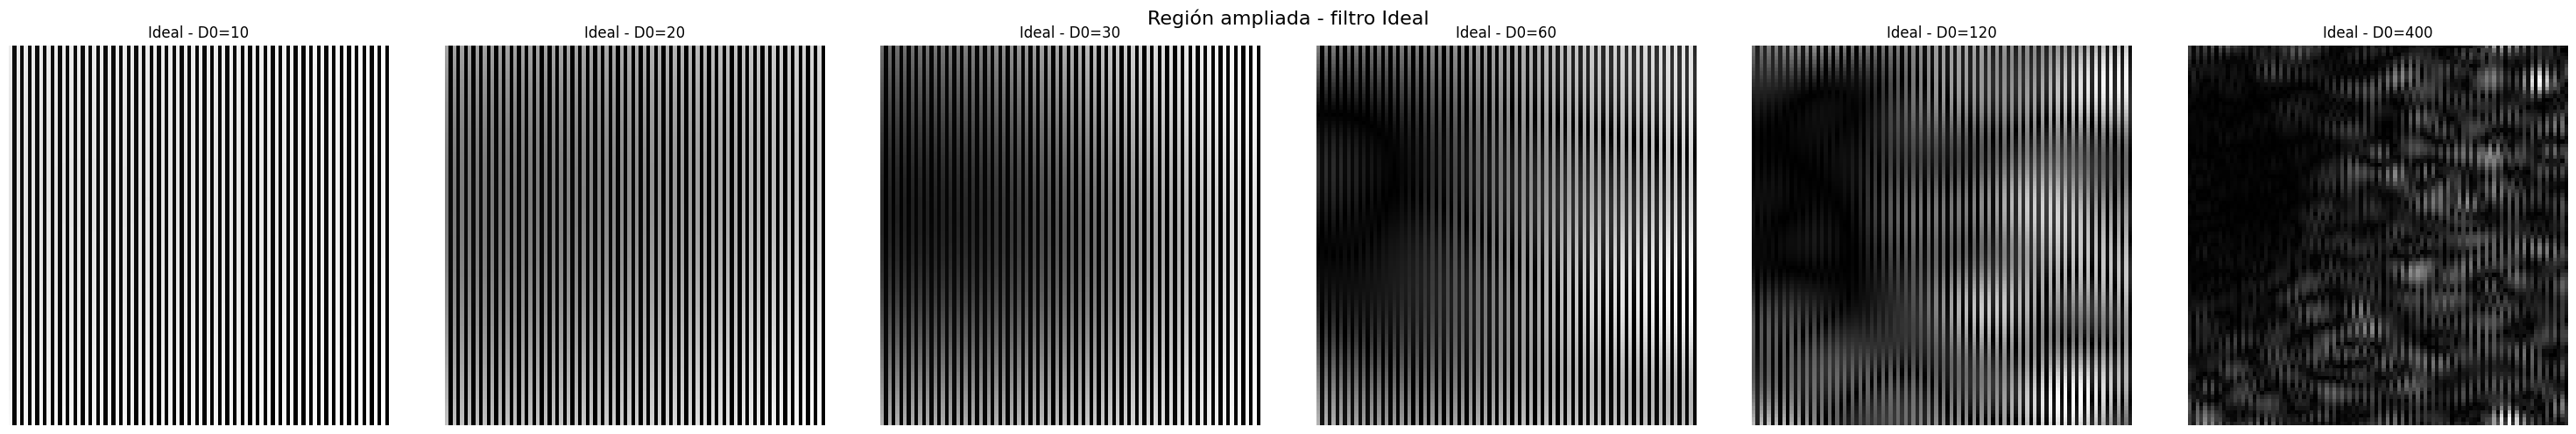

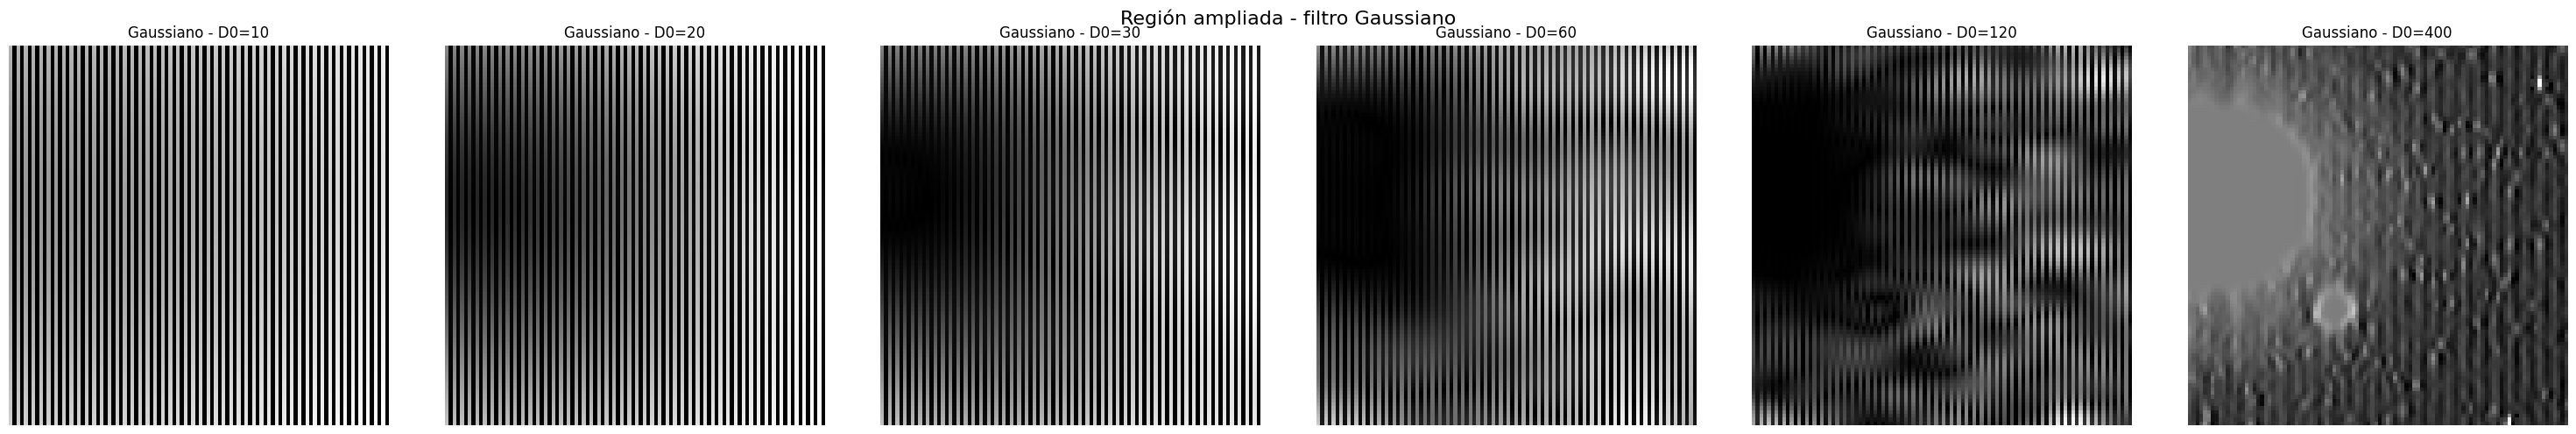

In [9]:
# Zoom para observar la región de interés
y1, y2 = 1050, 1150
x1, x2 = 3350, 3450

for tipo in ["ideal", "gaussiano"]:
    d0s = sorted(resultados_radio[tipo].keys())

    fig, axes = plt.subplots(
        1,
        len(d0s),
        figsize=(5 * len(d0s), 5),
        squeeze=False
    )
    axes = axes[0]

    for ax, d0 in zip(axes, d0s):
        roi = resultados_radio[tipo][d0]["diferencia"][y1:y2, x1:x2]

        ax.imshow(roi, cmap="gray")
        ax.set_title(f"{tipo.capitalize()} - D0={d0}")
        ax.axis("off")

    fig.suptitle(f"Región ampliada - filtro {tipo.capitalize()}", fontsize=16)
    plt.tight_layout()
    plt.show()


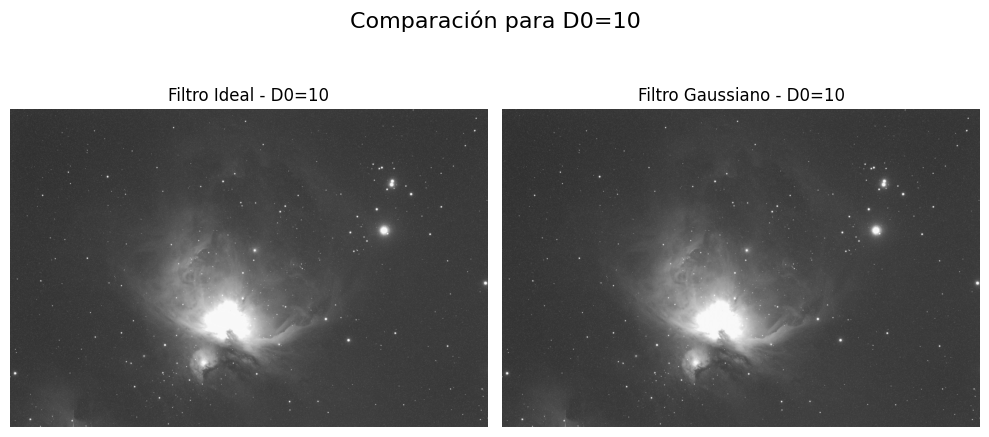

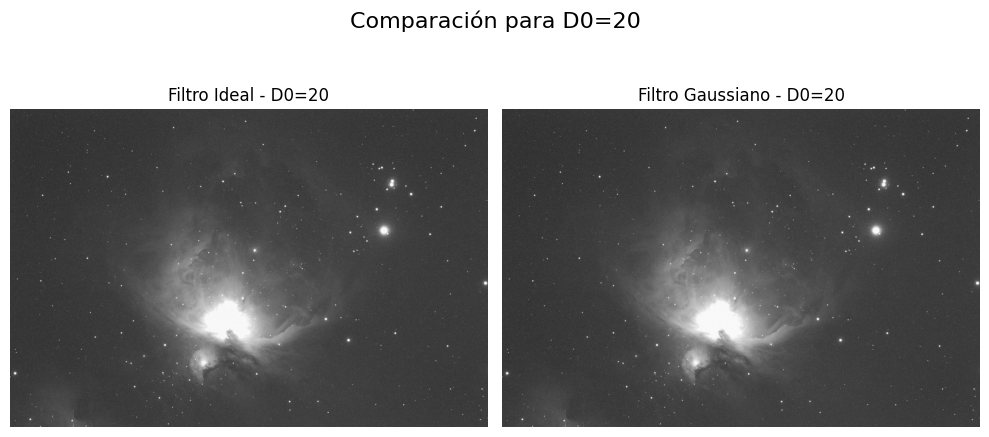

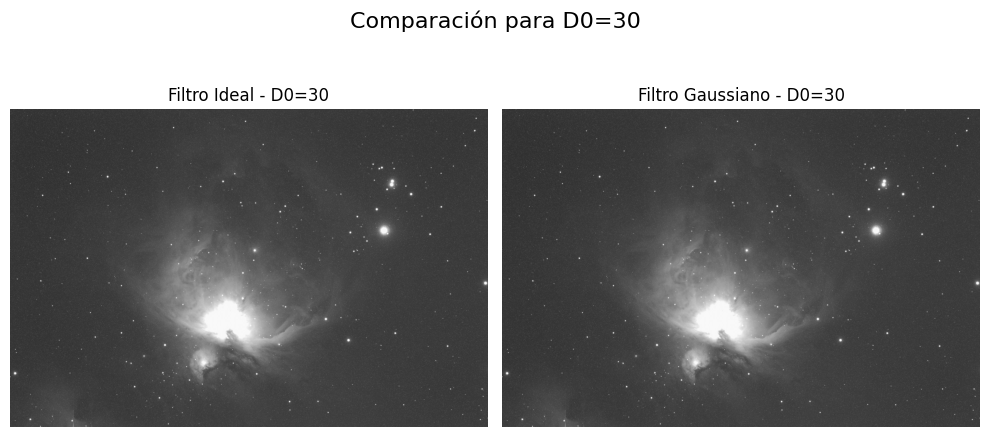

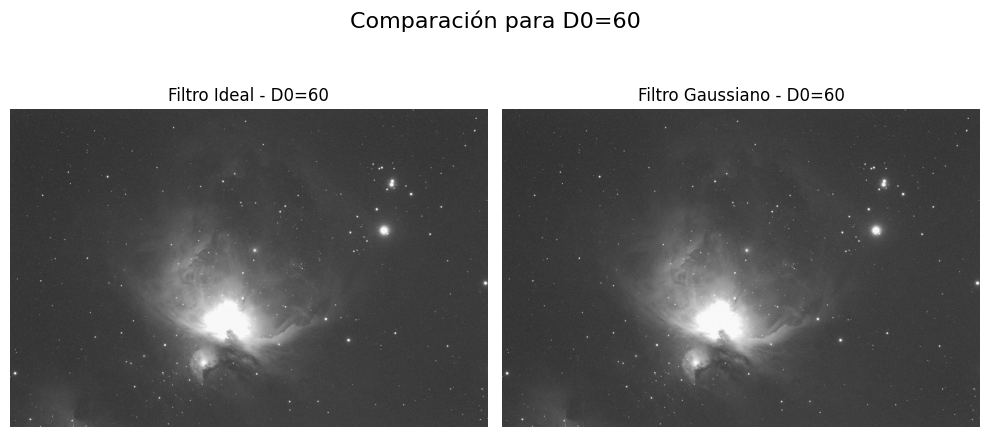

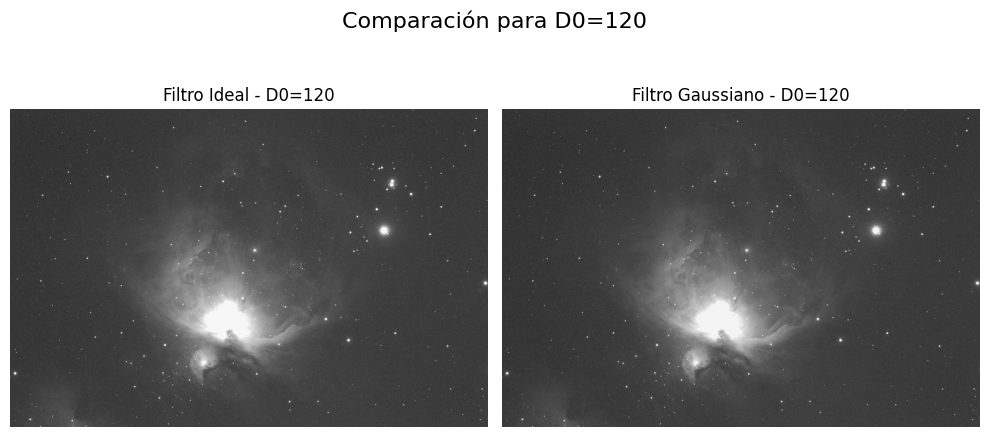

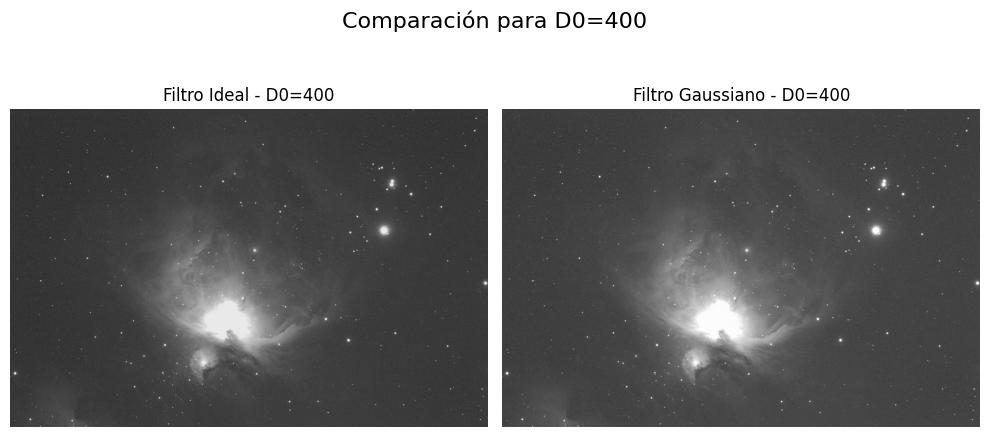

In [10]:
d0s = sorted(
    set(resultados_radio["ideal"].keys())
    & set(resultados_radio["gaussiano"].keys())
)

for d0 in d0s:
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for ax, tipo in zip(axes, ["ideal", "gaussiano"]):
        roi = resultados_radio[tipo][d0]["imagen"]

        ax.imshow(roi, cmap="gray")
        ax.set_title(f"Filtro {tipo.capitalize()} - D0={d0}")
        ax.axis("off")

    fig.suptitle(f"Comparación para D0={d0}", fontsize=16)
    plt.tight_layout()
    plt.show()

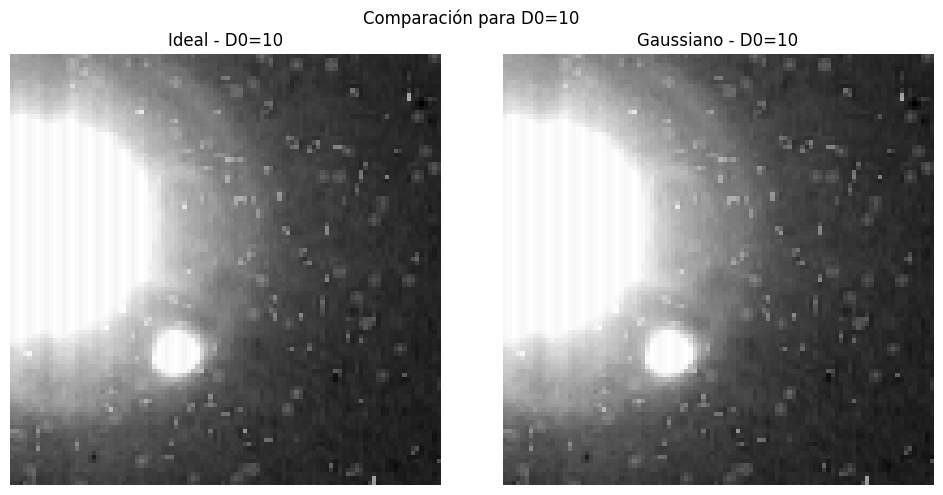

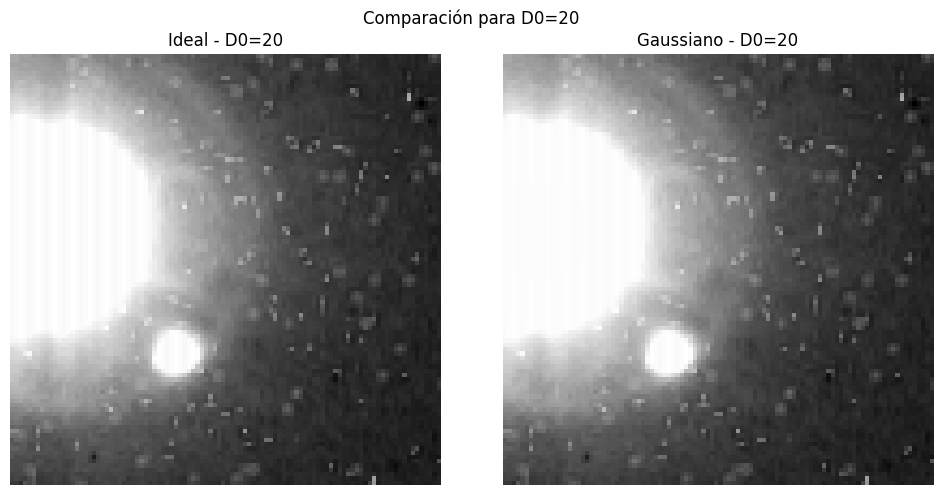

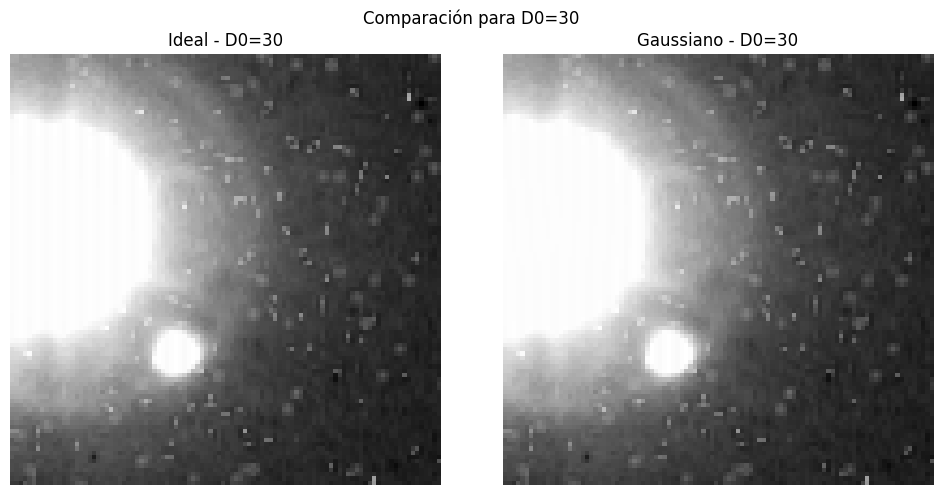

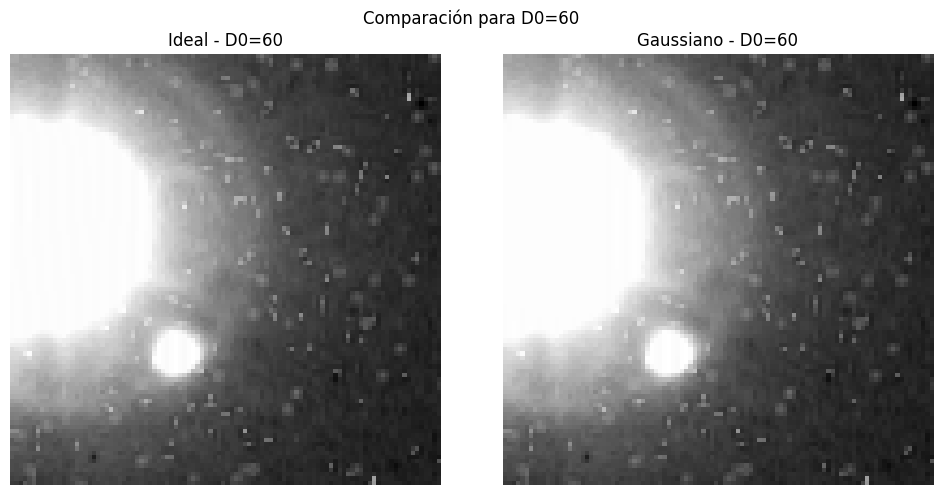

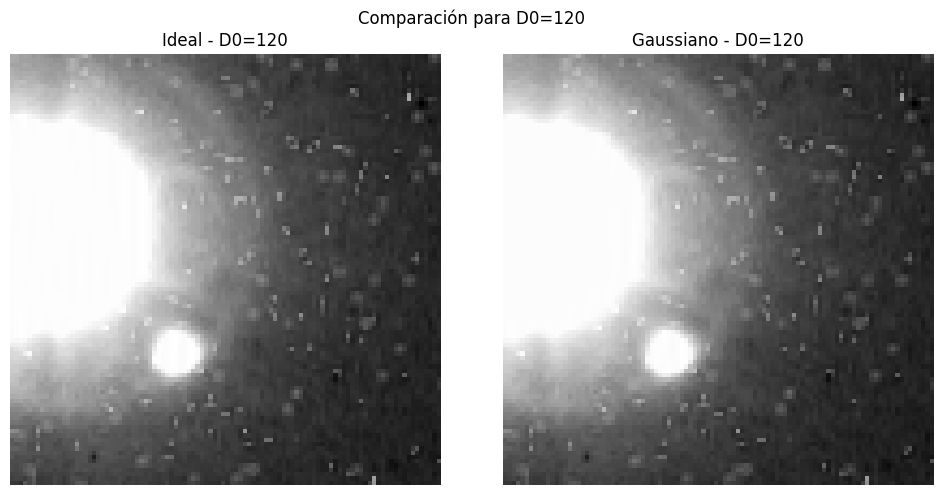

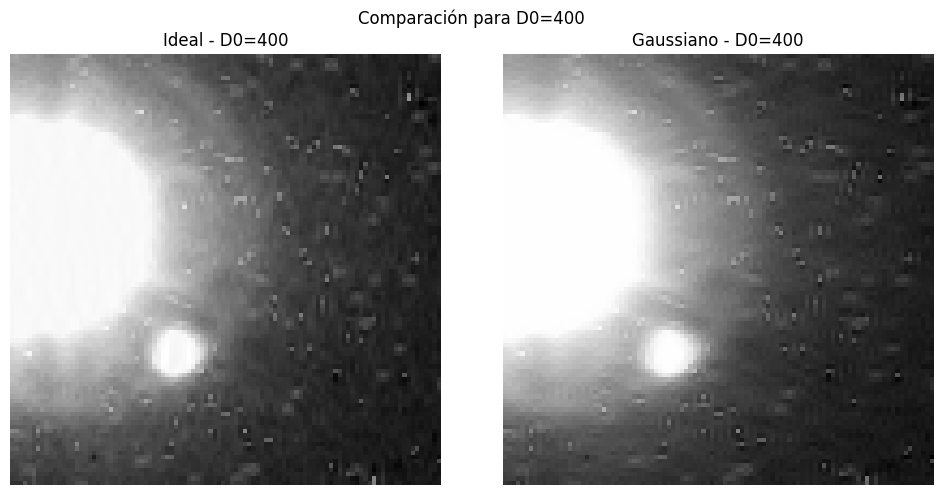

In [11]:
# Región que se desea ampliar
y1, y2 = 1050, 1150
x1, x2 = 3350, 3450

d0s = sorted(
    set(resultados_radio["ideal"].keys())
    & set(resultados_radio["gaussiano"].keys())
)

for d0 in d0s:
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for ax, tipo_filtro in zip(axes, ["ideal", "gaussiano"]):
        roi = resultados_radio[tipo_filtro][d0]["imagen"][
            y1:y2, x1:x2
        ]

        ax.imshow(
            roi,
            cmap="gray",
            interpolation="nearest"
        )
        ax.set_title(f"{tipo_filtro.capitalize()} - D0={d0}")
        ax.axis("off")

    fig.suptitle(f"Comparación para D0={d0}")
    plt.tight_layout()
    plt.show()

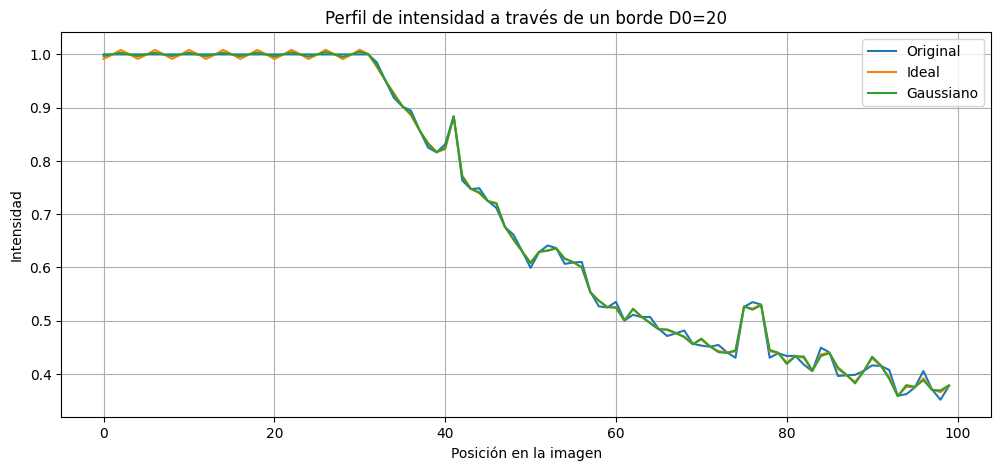

In [12]:
fila = 1100
x1, x2 = 3350, 3450
res_ideal = resultados_radio["ideal"][20]
res_gauss = resultados_radio["gaussiano"][20]

plt.figure(figsize=(12, 5))

plt.plot(img[fila, x1:x2], label="Original")
plt.plot(res_ideal["imagen"][fila, x1:x2], label="Ideal")
plt.plot(res_gauss["imagen"][fila, x1:x2], label="Gaussiano")

plt.xlabel("Posición en la imagen")
plt.ylabel("Intensidad")
plt.title("Perfil de intensidad a través de un borde D0=20")
plt.legend()
plt.grid()
plt.show()

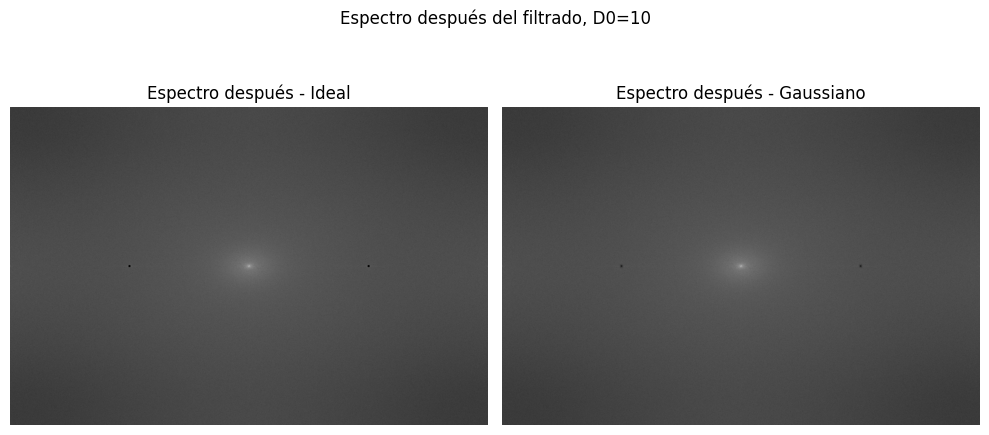

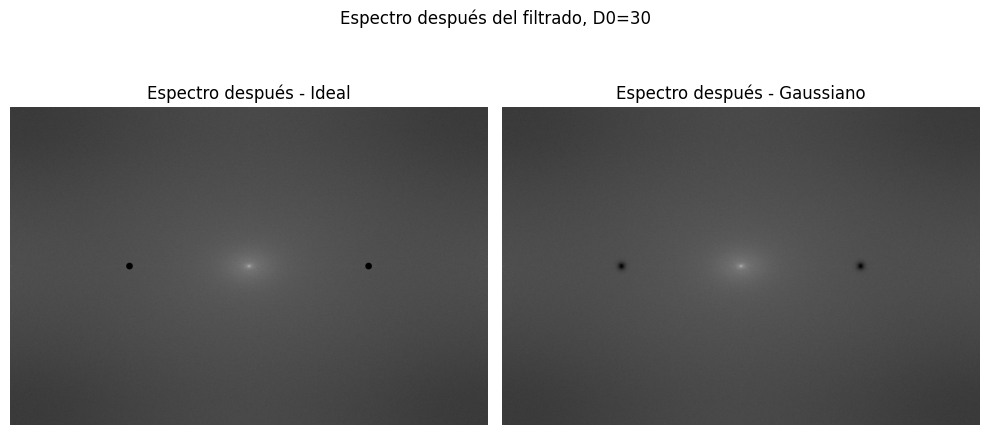

In [13]:
D0_CASOS = [10, 30]

for D0 in D0_CASOS:
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for ax, tipo in zip(axes, ("ideal", "gaussiano")):
        ns = [(u, v, float(D0)) for u, v in centros_notch]

        res = p1.filtrar_frecuencia_notch(
            img,
            ns,
            tipo,
            modo_padding="none",
            factor_padding=1.0,
            devolver_detalle=True
        )

        ax.imshow(res["espectro_despues"], cmap="gray")
        ax.set_title(f"Espectro después - {tipo.capitalize()}")
        ax.axis("off")

    fig.suptitle(f"Espectro después del filtrado, D0={D0}")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

Se evalúa el comportamiento de los filtros Notch ideales y gaussianos variando el radio de corte ($D_0 \in \{10, 20, 30, 60, 120\}$). Mediante la visualización de las imágenes filtradas, los mapas de diferencia absoluta bajo una escala común y recortes en regiones de interés (ROI), se analiza el compromiso entre la eliminación del ruido periódico y la preservación de los detalles estructurales:
* Ruido Residual ($D_0$ bajos, ej. 10): Se observa un sub-filtrado evidente. Los radios reducidos son insuficientes para cubrir completamente la extensión espectral de los picos de ruido, provocando que el patrón de rayas permanezca visible en la imagen espacial.

* Compromiso Óptimo ($D_0$ intermedios, ej. 30): Representan el punto de equilibrio adecuado. El ruido periódico es eliminado en gran parte sin incurrir en una degradación masiva de la nebulosa ni de las estrellas.

* Pérdida de Detalle y Artefactos ($D_0$ altos, ej. 60–120): Un radio excesivamente amplio (como $D_0 = 120$) amplía de forma drástica la zona de exclusión en el dominio de la frecuencia, suprimiendo componentes estructurales legítimas de la imagen y generando texturas ruidosas generalizadas y artefactos de modulación en los mapas de diferencia.

* Comparativa Ideal vs. Gaussiano: Al analizar los perfiles de intensidad en bordes de una estrella, se observa que el filtro Notch ideal induce oscilaciones (ringing o fenómeno de Gibbs) en los picos de intensidad debido a su corte abrupto en el dominio de la frecuencia. Por el contrario, el filtro Gaussiano elimina eficientemente el ruido periódico sin introducir estas ondas artificiales, garantizando una respuesta suave y justificando su selección analítica para el procesamiento de la imagen astronómica.

### 3. Compare el filtrado sin padding con la estrategia de extensión que proponga. Explore al menos dos  tamaños de extensión y analice los bordes mediante recortes ampliados. Seleccione y justifique la estrategia de padding utilizada en el resto de la pregunta. 

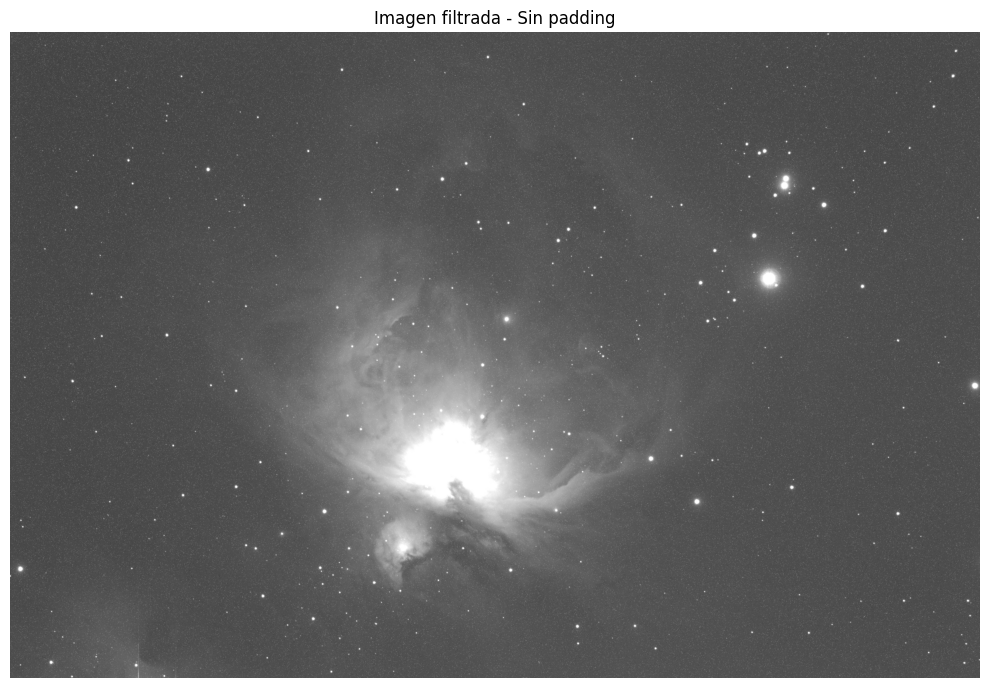

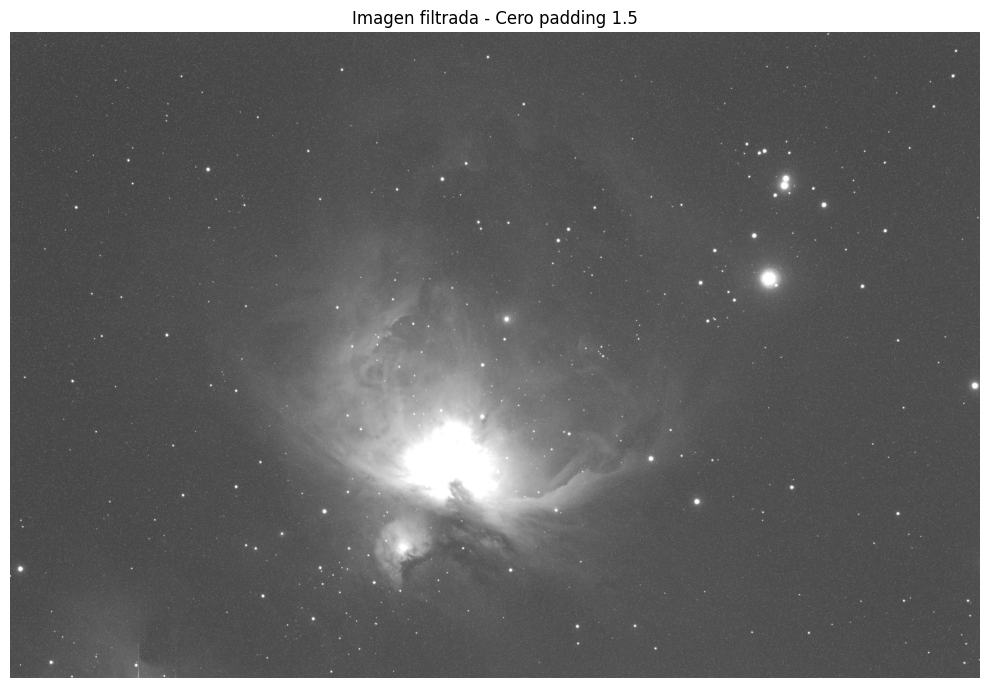

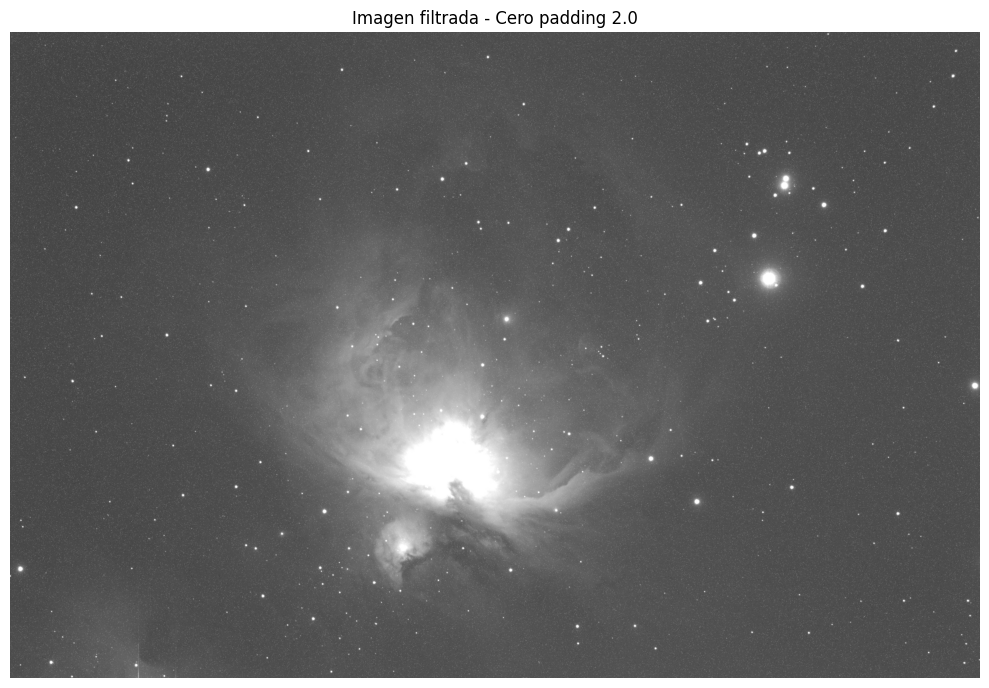

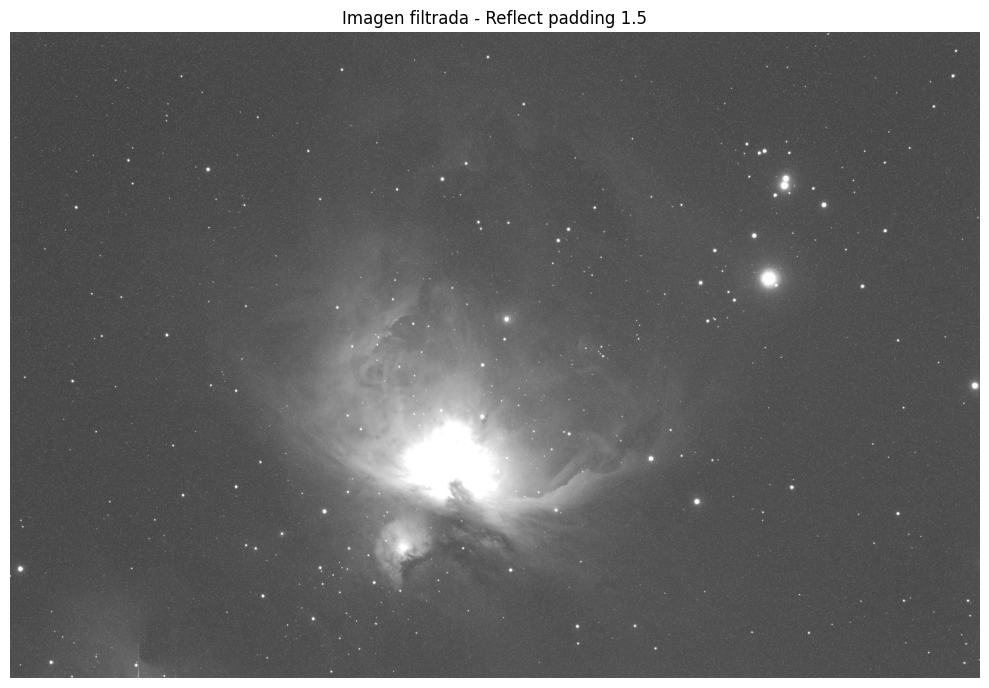

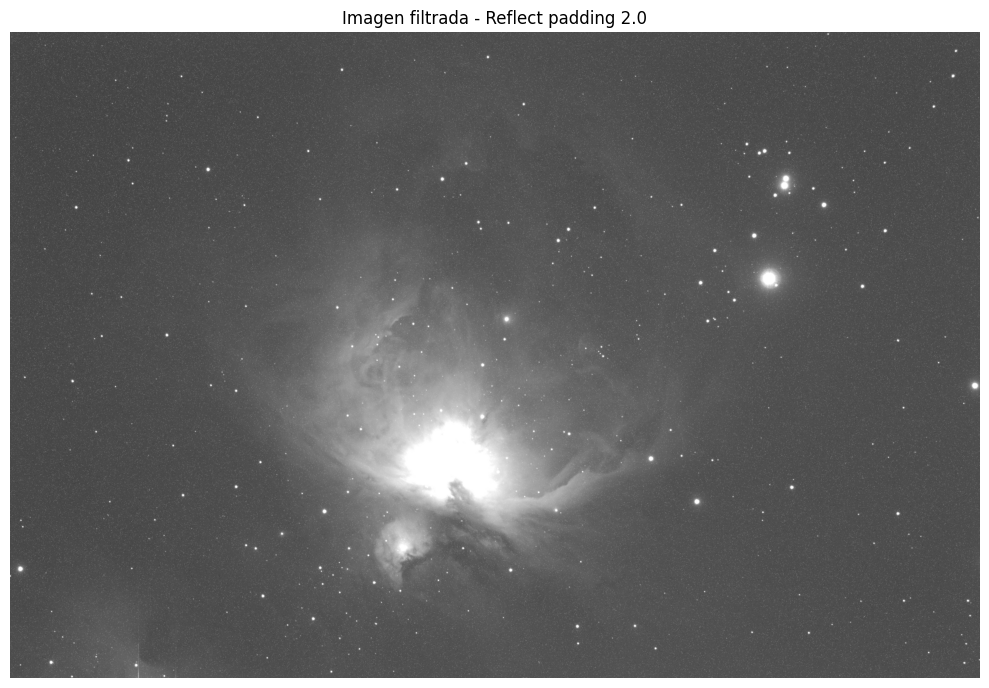

In [14]:
D0_PADDING = 30
notches_padding = [(u,v,D0_PADDING) for u,v in centros_notch]
config_padding = [
    ("Sin padding","none",1.0),
    ("Cero padding 1.5","constant",1.5),
    ("Cero padding 2.0","constant",2.0),
    ("Reflect padding 1.5","reflect",1.5),
    ("Reflect padding 2.0","reflect",2.0)
]
resultados_padding_vis = {}
for nombre,modo,factor in config_padding:
    res = p1.filtrar_frecuencia_notch(img,notches_padding,"gaussiano",modo,factor)
    resultados_padding_vis[nombre] = {
        "imagen":res["imagen"],
    }
    del res

# Una figura por cada configuración de padding
for nombre,_,_ in config_padding:
    plt.figure(figsize=(10, 10))
    plt.imshow(resultados_padding_vis[nombre]["imagen"], cmap="gray", vmin=0, vmax=1)
    plt.title(f"Imagen filtrada - {nombre}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close()

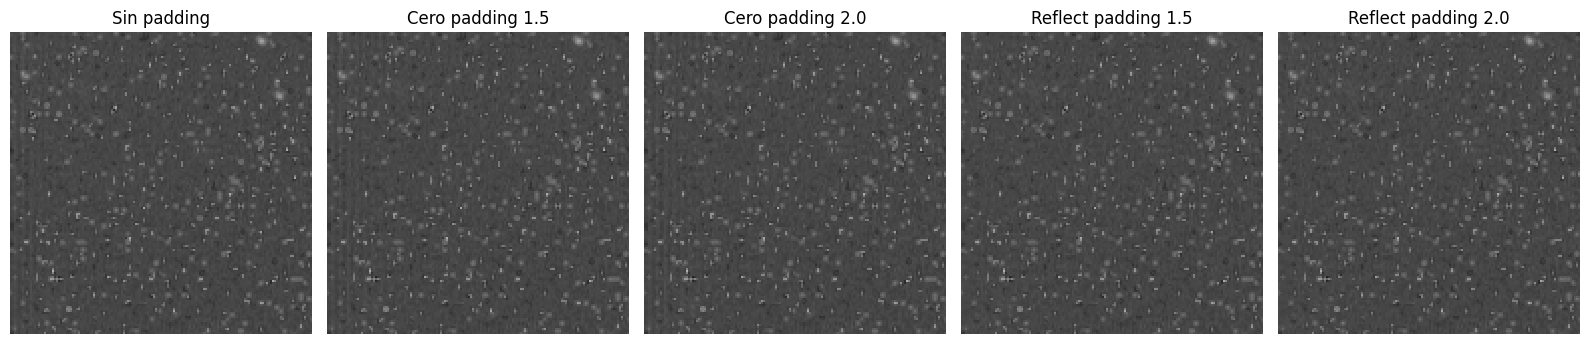

In [15]:
TAM_CROP = 150

fig, axes = plt.subplots(1, len(config_padding), figsize=(16, 5))

for ax, (nombre, modo, factor) in zip(axes, config_padding):

    res = p1.filtrar_frecuencia_notch(
        img, notches_padding, "gaussiano", modo, factor
    )

    esquina = res["imagen"][:TAM_CROP, :TAM_CROP]

    ax.imshow(
        esquina,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(nombre)
    ax.axis("off")

    del res

plt.tight_layout()
plt.show()

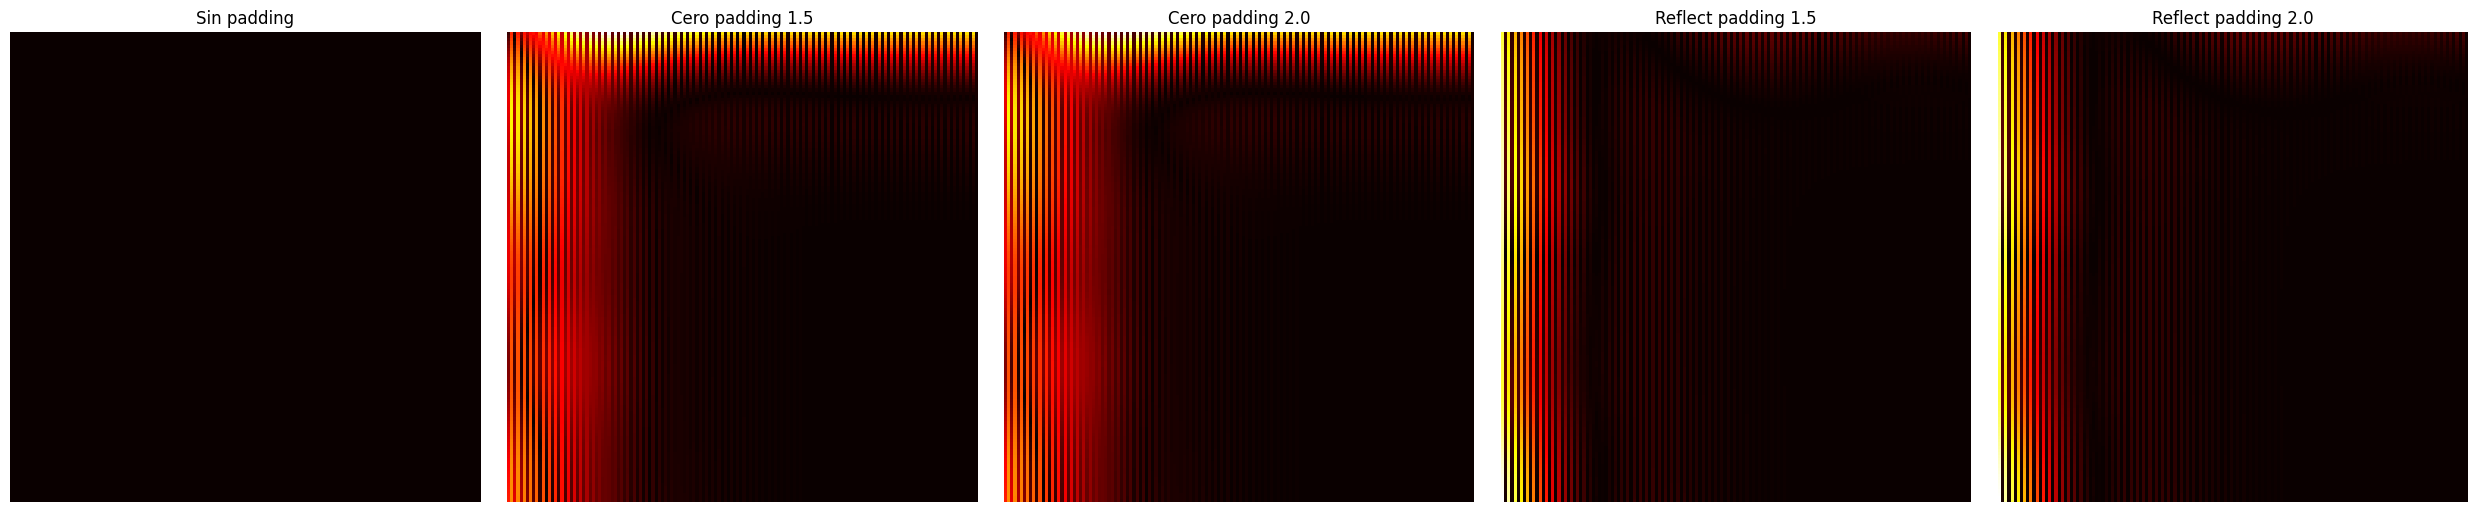

In [16]:
referencia = resultados_padding_vis["Sin padding"]["imagen"]

n_configs = len(config_padding)
fig, axes = plt.subplots(
    1,
    n_configs,
    figsize=(5 * n_configs, 5),
    squeeze=False
)

axes = axes[0]

for ax, (nombre, modo, factor) in zip(axes, config_padding):
    res = p1.filtrar_frecuencia_notch(
        img,
        notches_padding,
        "gaussiano",
        modo,
        factor
    )

    diferencia = np.abs(referencia - res["imagen"])

    ax.imshow(
        diferencia[:150, :150],
        cmap="hot",
        interpolation="nearest"
    )

    ax.set_title(nombre)
    ax.axis("off")

plt.tight_layout()
plt.show()

Se evaluó el comportamiento de borde comparando el filtrado sin padding frente a dos estrategias de extensión (zero-padding y reflect-padding) bajo factores de escala de $1.5$ y $2.0$.

Al inspeccionar los mapas de diferencia absoluta en las esquinas se observa lo siguiente:

* Zero-Padding: Introduce una discontinuidad abrupta de intensidad en la frontera. Dado que la DFT supone periodicidad en la imagen, esta transición abrupta genera componentes espurias de alta frecuencia que se propagan hacia el interior de la matriz como artefactos de borde y solapamiento por convolución circular.

* Reflect-Padding: Preserva la continuidad de intensidad en los límites espaciales, confinando las alteraciones exclusivamente al margen externo y protegiendo la estructura interna de la imagen.

* Factor de Extensión ($2.0$): Para evitar el error de envoltura (wraparound error) al multiplicar en frecuencia y asegurar una convolución lineal efectiva, la teoría exige extender las dimensiones al menos al doble ($P \ge 2M$).

Selección Definitiva: Se adopta Reflect-Padding con un factor de $2.0$, ya que garantiza la continuidad en las fronteras y satisface el tamaño mínimo para evitar el solapamiento de réplicas periódicas en la DFT.

### 4. Seleccione finalmente una configuración de filtro que considere adecuada y justifique el compromiso adoptado entre eliminación del patrón periódico y conservación de información. 

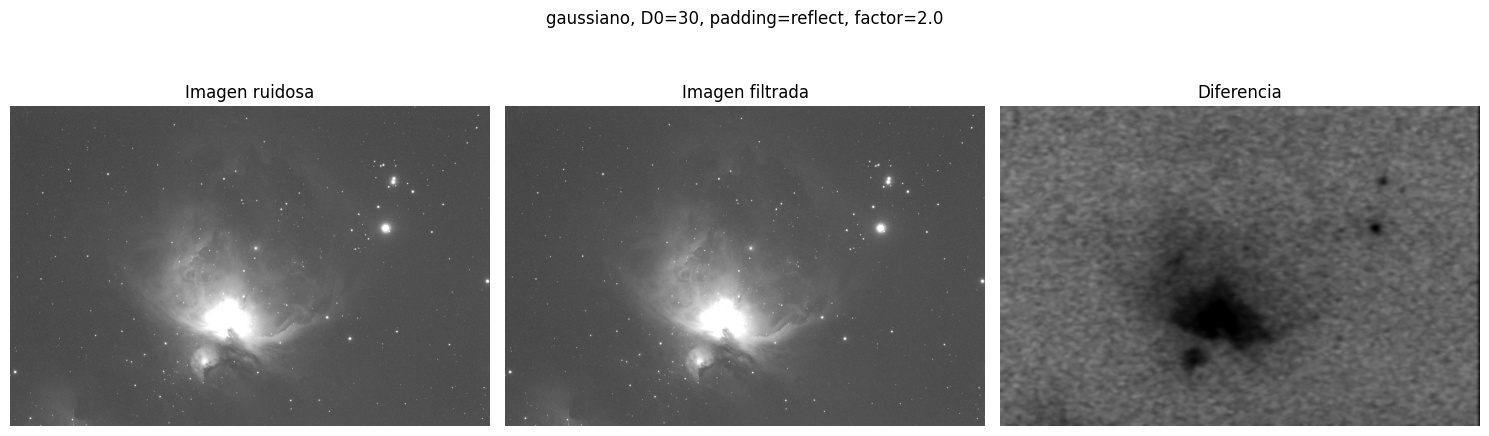

In [17]:
TIPO_FINAL = "gaussiano"
D0_FINAL = 30
MODO_PADDING_FINAL = "reflect"
FACTOR_PADDING_FINAL = 2.0

notches_finales = [(u,v,D0_FINAL) for u,v in centros_notch]
resultado_final = p1.filtrar_frecuencia_notch(
    img,
    notches_finales,
    TIPO_FINAL,
    MODO_PADDING_FINAL,
    FACTOR_PADDING_FINAL,
    devolver_detalle=True
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Imagen ruidosa")
axes[0].axis("off")

axes[1].imshow(
    resultado_final["imagen"],
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1].set_title("Imagen filtrada")
axes[1].axis("off")

axes[2].imshow(
    resultado_final["diferencia"],
    cmap="gray",
)
axes[2].set_title("Diferencia")
axes[2].axis("off")

plt.suptitle(
    f"{TIPO_FINAL}, D0={D0_FINAL}, "
    f"padding={MODO_PADDING_FINAL}, factor={FACTOR_PADDING_FINAL}"
)

plt.tight_layout()
plt.show()

Se adoptó la combinación Filtro Gaussiano, $D_0 = 30$, Reflect-Padding y Factor $2.0$ basándose en los siguientes compromisos teóricos:
1. Filtro Gaussiano: Debido a que filtro ideal introduce oscilaciones o artefactos espurios de ringing (efecto Gibbs) en el dominio espacial.
2. .Compromiso en el Radio de Corte ($D_0 = 30$): Representa el punto de equilibrio (trade-off) entre eliminación de ruido y conservación de detalles:
    - Un radio demasiado angosto ($D_0 < 30$) no cubre toda la energía distribuida en las bandas laterales del impulso de ruido.
    - Un radio excesivo ($D_0 > 30$) remueve frecuencias de la imagen original adyacentes al notch, difuminando estructuras finas y detalles de alta frecuencia.
3. Estrategia de Padding (reflect, factor $2.0$):
    - Reflect-Padding: Preserva la continuidad de intensidades en los límites de la matriz, evitando saltos abruptos que inyecten componentes espurias de alta frecuencia en la DFT
    - Factor $2.0$: Satisface la condición teórica de extensión ($P \ge 2M$) para evitar el solapamiento circular (wraparound error) durante la multiplicación espectral, garantizando una convolución lineal sobre la escena de interés.

## Figuras Extras Informe

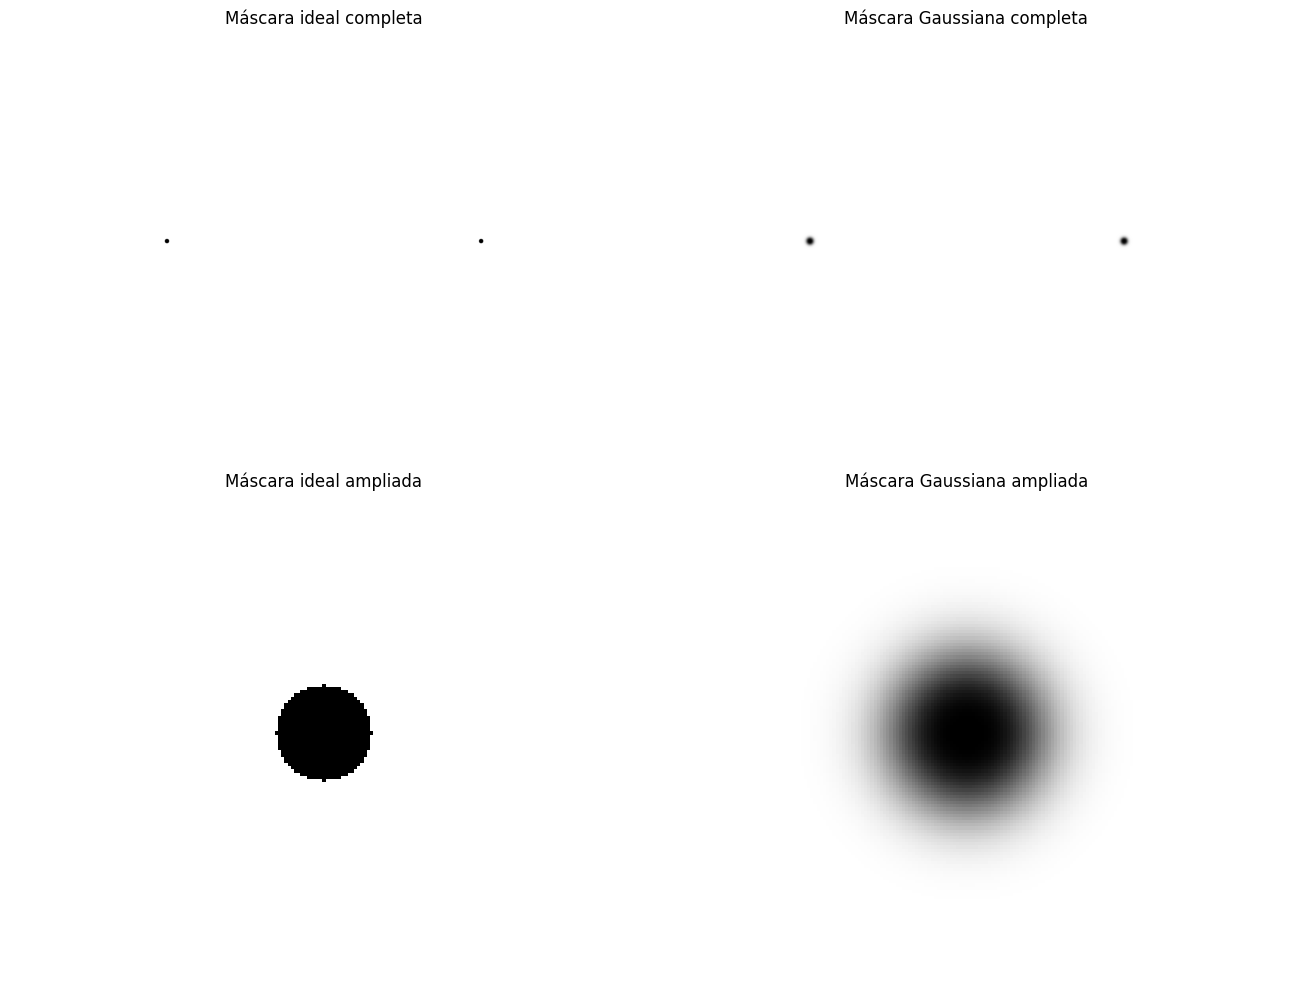

In [18]:
# Visualizar mascaras de filtrado notch
D0_inicial = 15
notches_iniciales = [(u,v,D0_inicial) for u,v in centros_notch]
H_ideal = p1.construir_filtro_notch(img.shape, notches_iniciales, "ideal")
H_gauss = p1.construir_filtro_notch(img.shape, notches_iniciales, "gaussiano")

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].imshow(
    H_ideal,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0, 0].set_title("Máscara ideal completa")
axes[0, 0].axis("off")

axes[0, 1].imshow(
    H_gauss,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0, 1].set_title("Máscara Gaussiana completa")
axes[0, 1].axis("off")

uk, vk = centros_notch[0]
cy, cx = img.shape[0] // 2, img.shape[1] // 2
rv = max(30, int(5 * D0_inicial))

yc, xc = int(round(cy + uk)), int(round(cx + vk))

y0, y1 = max(0, yc - rv), min(H_ideal.shape[0], yc + rv + 1)
x0, x1 = max(0, xc - rv), min(H_ideal.shape[1], xc + rv + 1)

axes[1, 0].imshow(
    H_ideal[y0:y1, x0:x1],
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)
axes[1, 0].set_title("Máscara ideal ampliada")
axes[1, 0].axis("off")

axes[1, 1].imshow(
    H_gauss[y0:y1, x0:x1],
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)
axes[1, 1].set_title("Máscara Gaussiana ampliada")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()